In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('clean_ecom.csv')
df.isna().sum()

order_id               0
customer_id            0
order_date             0
product_category       0
product_name           0
quantity               0
unit_price             0
discount_pct           0
payment_method         0
shipping_city          0
country                0
order_status           0
customer_rating     5422
revenue                0
dtype: int64

<Axes: xlabel='revenue', ylabel='Count'>

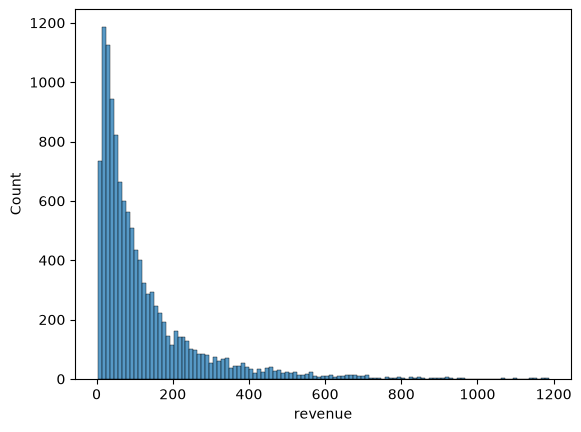

In [2]:
# What is the overall distribution of revenue per order?
# Histogram + KDE
# Find typical order revenue, skewness, and unusually high-value orders.

sns.histplot(data=df,x='revenue')

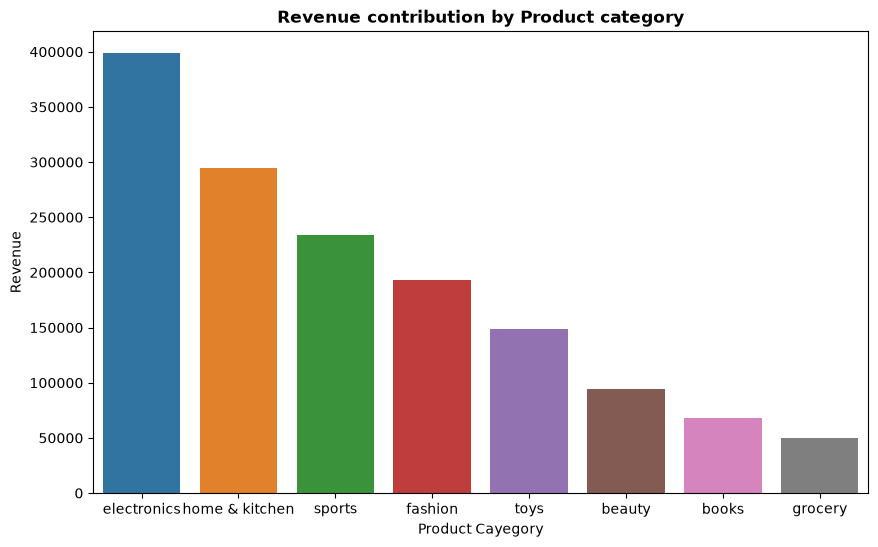

In [3]:
# Which product categories generate the highest revenue?
# Bar plot
# Compare category performance and identify major revenue contributors

revenue_contri = df.groupby(['product_category'])['revenue'].sum().reset_index().sort_values(by='revenue', ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(data=revenue_contri,x='product_category',y='revenue',hue='product_category')
plt.title('Revenue contribution by Product category', fontsize=12, fontweight='bold')
plt.xlabel('Product Cayegory')
plt.ylabel('Revenue')
plt.show()


<Axes: xlabel='product_category', ylabel='order_count'>

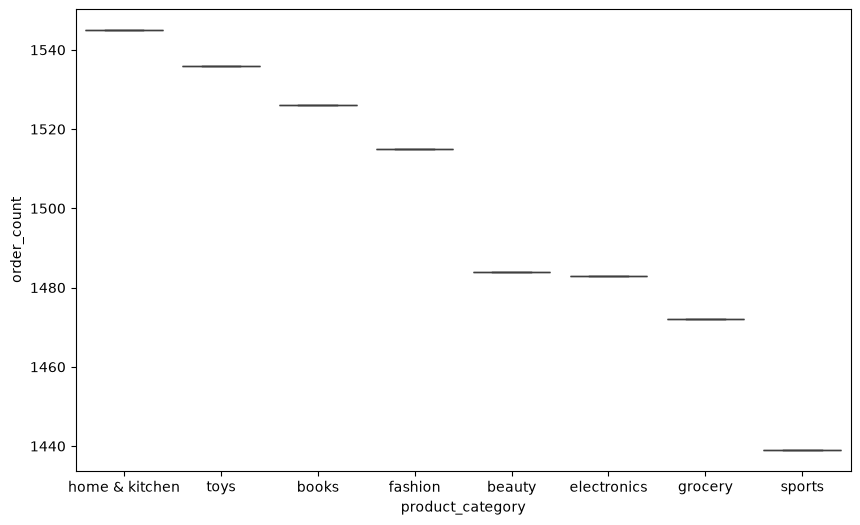

In [4]:
# How does quantity sold vary across product categories?
# Box plot
# Compare typical quantities, spread, and potential outliers.

count_category = df.groupby(['product_category'])['order_id'].count().reset_index(name='order_count').sort_values(by='order_count', ascending=False)


plt.figure(figsize=(10,6))
sns.boxplot(data=count_category,x='product_category',y='order_count')

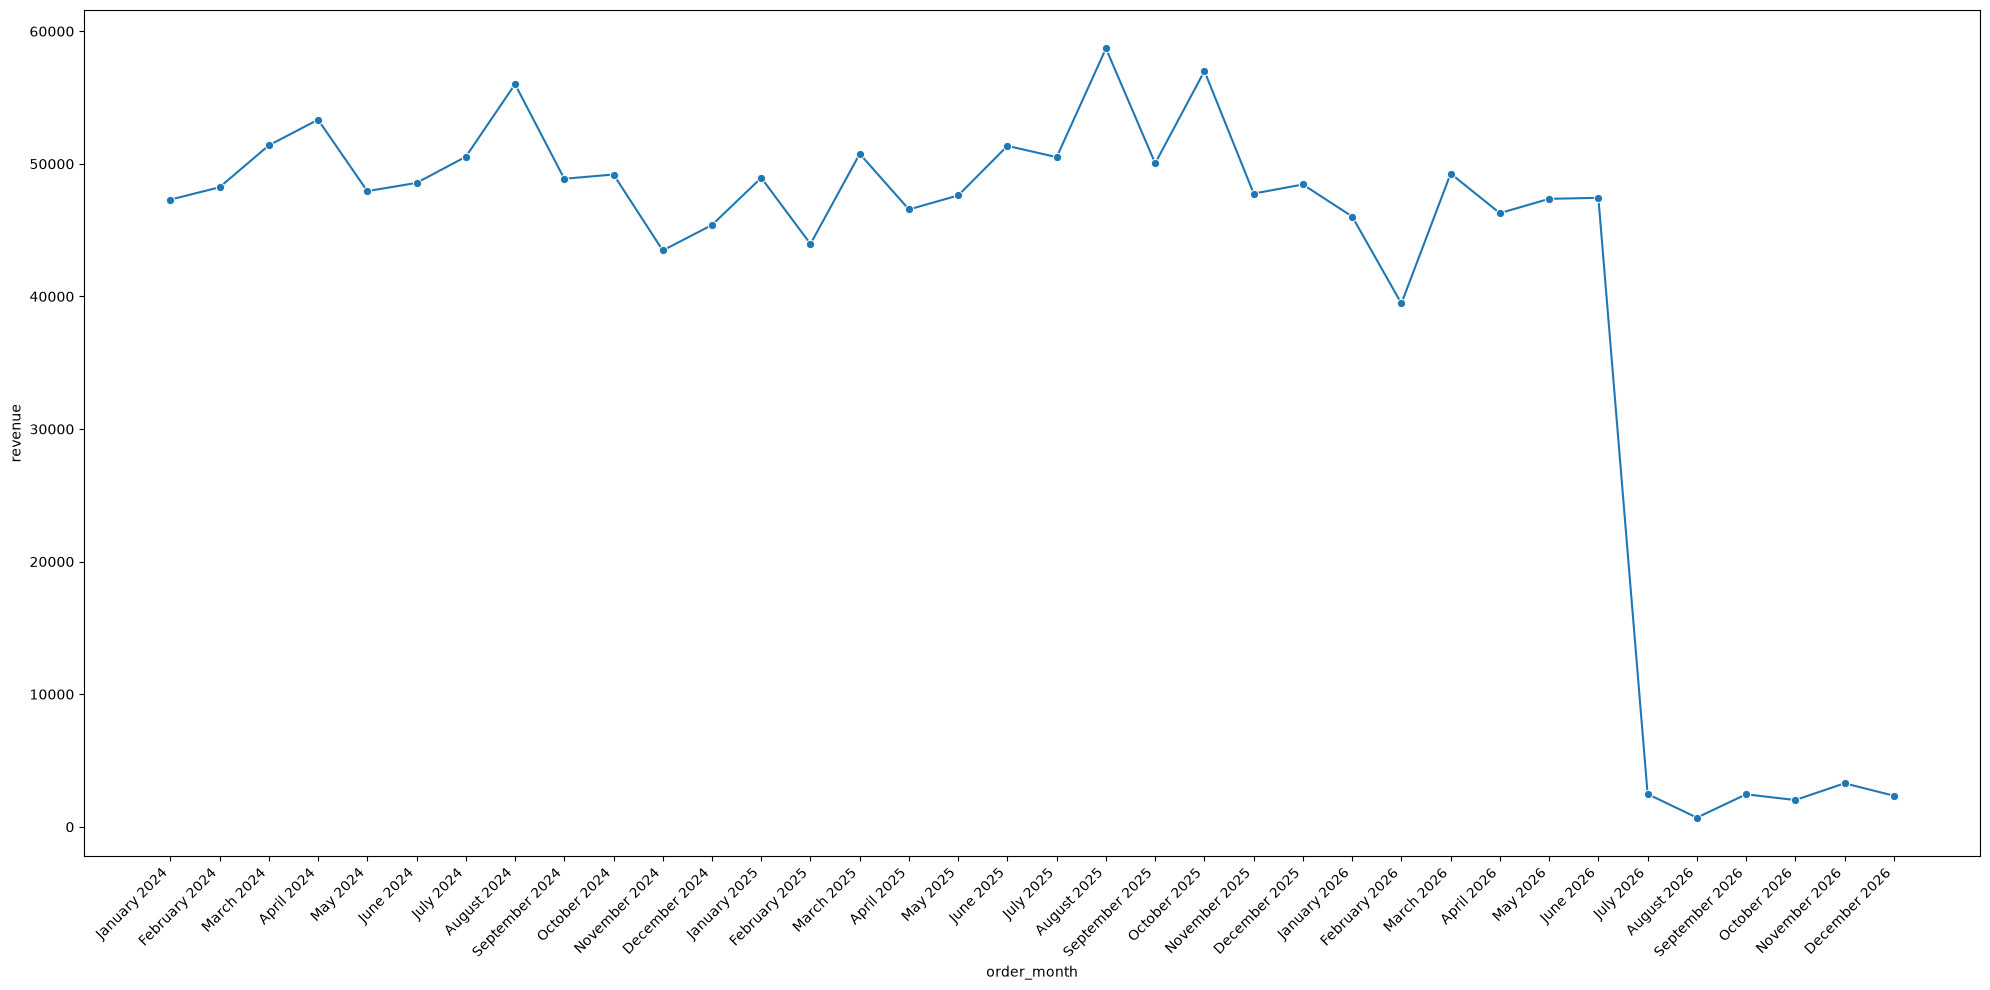

In [5]:
# How does revenue change over time?
# Line plot
# Identify growth, seasonal patterns, and revenue peaks using order_date.


# 1. Convert to datetime and create a Period column for correct chronological sorting
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed', errors='coerce')
df['year_month'] = df['order_date'].dt.to_period('M')

# 2. Group ONLY by the month period and sum the revenue
revenue_by_month = df.groupby('year_month')['revenue'].sum().reset_index()

# 3. Create the readable month-year name for display
revenue_by_month['order_month'] = revenue_by_month['year_month'].dt.strftime('%B %Y')

# 4. Plot cleanly without confidence intervals (since it's now 1 data point per month)
plt.figure(figsize=(20, 10))
sns.lineplot(data=revenue_by_month, x='order_month', y='revenue', sort=False, marker='o')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

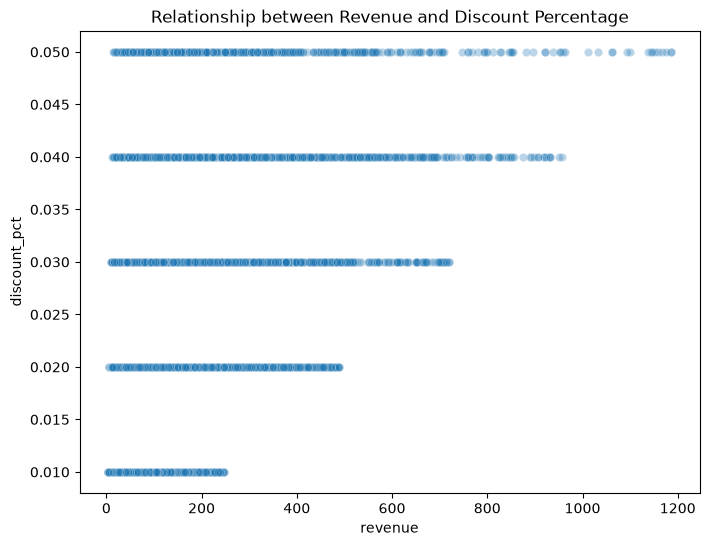

In [6]:
# Is discount percentage associated with revenue?
# Scatter plot
# Investigate the relationship between discount_pct and revenue. This is an association, not proof that discounts cause higher sales.
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='revenue', y='discount_pct', alpha=0.3)
plt.title('Relationship between Revenue and Discount Percentage')
plt.show()

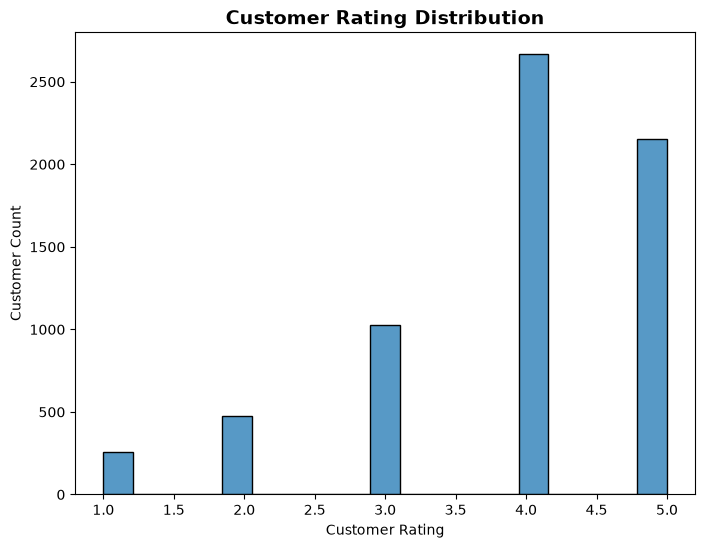

In [7]:
# How are customer ratings distributed?
# Histogram
# Determine whether customer feedback is generally positive or negative.

plt.figure(figsize=(8, 6))
sns.histplot(data=df,x='customer_rating')
plt.title('Customer Rating Distribution',fontsize=14,fontweight='bold')
plt.ylabel('Customer Count')
plt.xlabel('Customer Rating')
plt.show()

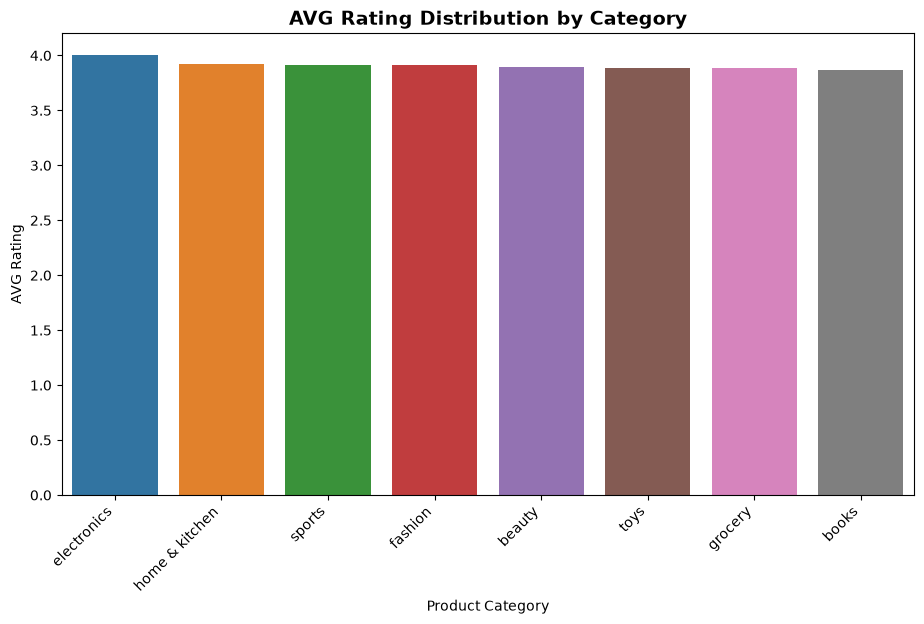

In [8]:
# Which product categories have the highest average customer ratings?
# Bar plot
# Compare customer satisfaction across product categories.

avg_rating = df.groupby(['product_category'])['customer_rating'].mean().reset_index().sort_values(by='customer_rating', ascending=False)

plt.figure(figsize=(11, 6))
sns.barplot(data=avg_rating,x='product_category',y='customer_rating',hue='product_category',legend=False)
plt.title('AVG Rating Distribution by Category',fontsize=14,fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.ylabel('AVG Rating')
plt.xlabel('Product Category')
plt.show()

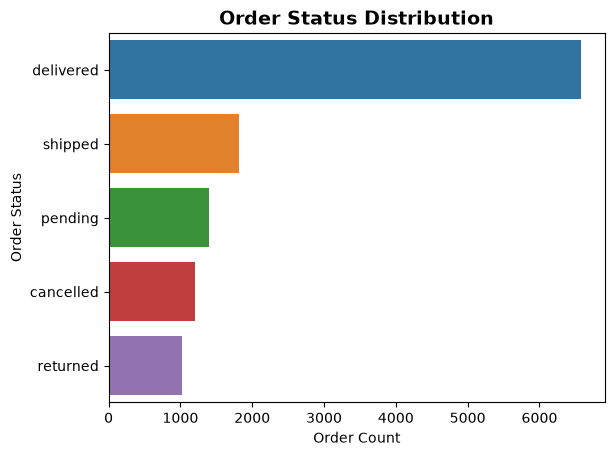

In [9]:
# What proportion of orders belongs to each order status?
# Count plot / pie chart
# Understand the composition of delivered, cancelled, returned, or other recorded statuses.

status_contri = df.groupby(['order_status'])['order_id'].count().reset_index(name='count').sort_values(by='count', ascending=False)

sns.barplot(data=status_contri, x='count', y='order_status', hue='order_status', legend=False)
plt.title('Order Status Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Order Count')
plt.ylabel('Order Status')
plt.show()

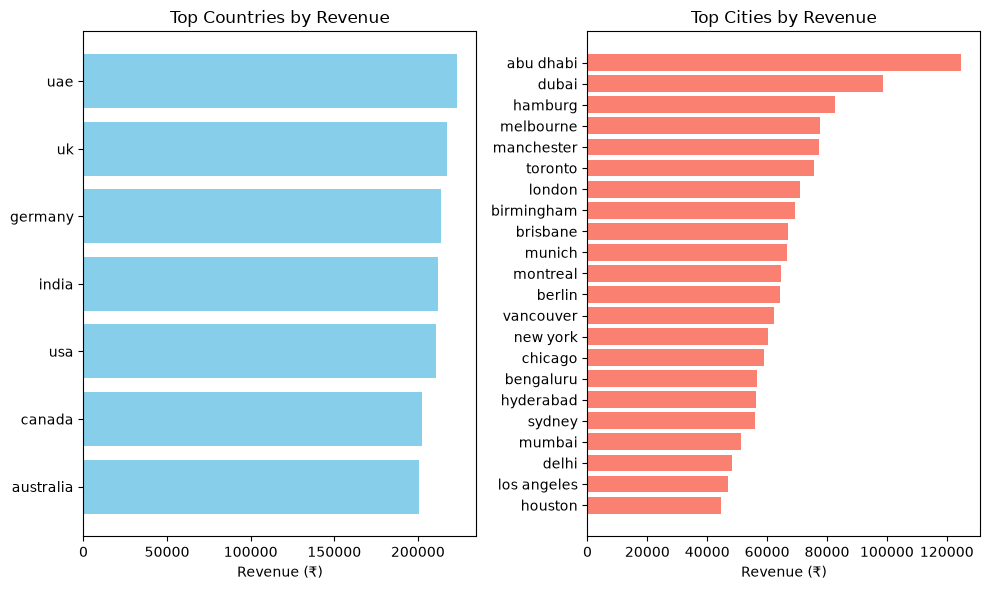

In [21]:
# Which cities and countries contribute most to revenue?
# Horizontal bar plot
# Identify strong markets and locations that may need additional attention.

top_countries = df.groupby('country')['revenue'].sum().reset_index().sort_values(by='revenue', ascending=True)
top_cities = df.groupby('shipping_city')['revenue'].sum().reset_index().sort_values(by='revenue', ascending=True)
fig, ax = plt.subplots(1,2 ,figsize=(10,6))

ax[0].barh(top_countries['country'], top_countries['revenue'], color='skyblue')
ax[0].set_title('Top Countries by Revenue')
ax[0].set_xlabel('Revenue (₹)')

ax[1].barh(top_cities['shipping_city'], top_cities['revenue'], color='salmon')
ax[1].set_title('Top Cities by Revenue')
ax[1].set_xlabel('Revenue (₹)')

plt.tight_layout()
plt.show()

<Axes: >

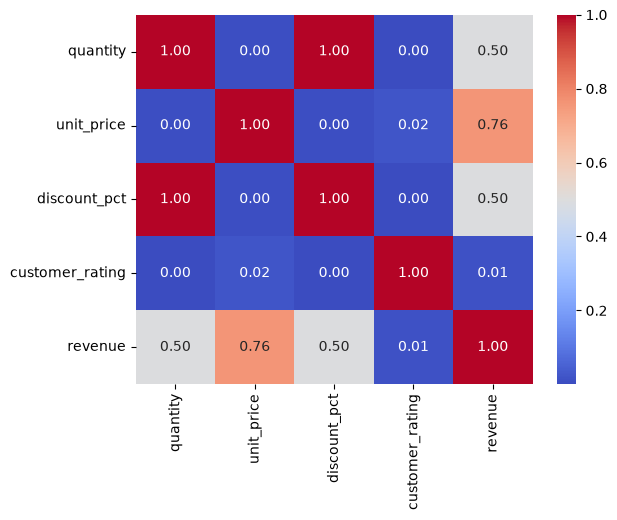

In [24]:
# What relationships exist among numerical variables?
# Correlation heatmap
# Explore relationships between quantity, unit price, discounts, revenue, and customer ratings.

# sns.heatmap(data=df,)
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')

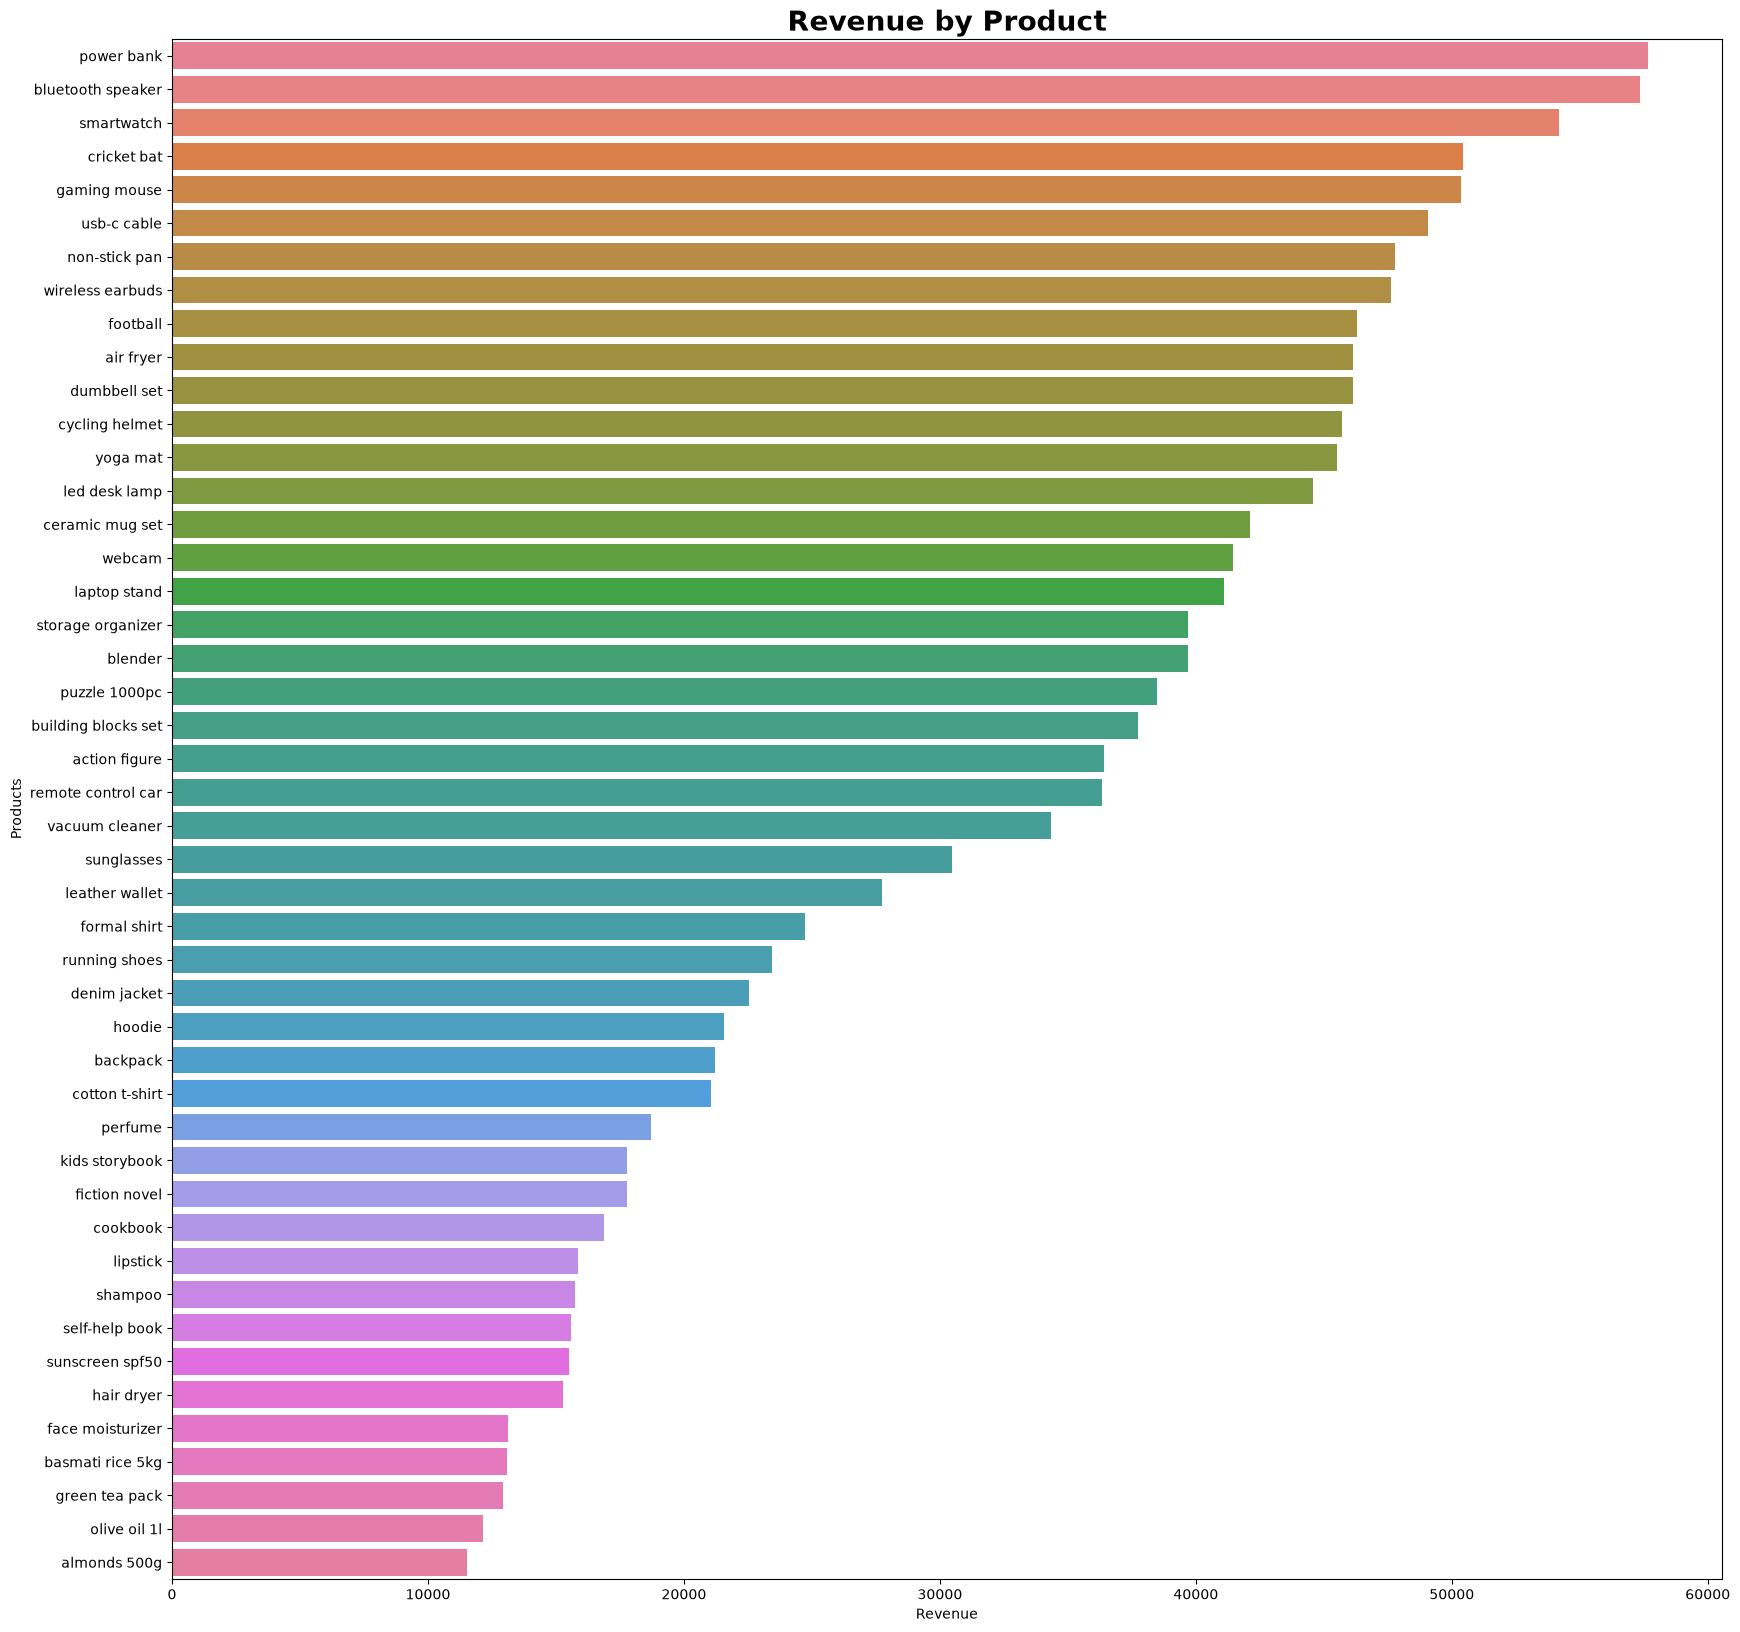

In [47]:
# 11. Which products have the highest and lowest total revenue? — horizontal bar plot.

product_revenue = df.groupby(['product_name'])['revenue'].sum().reset_index().sort_values(by='revenue', ascending=False)

plt.figure(figsize=(20,20))
sns.barplot(data=product_revenue,x='revenue',y='product_name',hue='product_name')
plt.title('Revenue by Product',fontsize=20,fontweight='bold')
plt.xlabel('Revenue')
plt.ylabel('Products')
plt.yticks(rotation=0, ha='right')
plt.show()

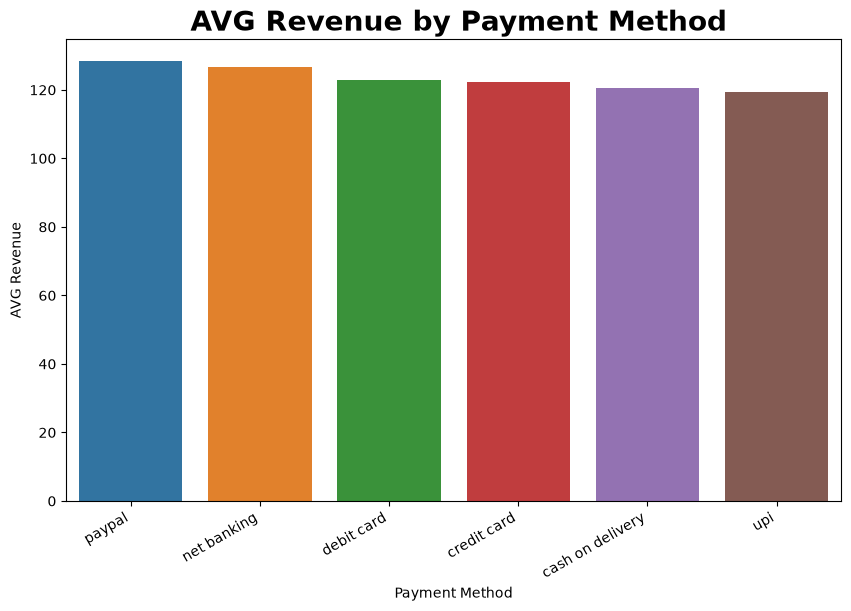

In [53]:
avg_revenue_method = df.groupby(['payment_method'])['revenue'].mean().reset_index().sort_values(by='revenue', ascending=False)
# print(avg_revenue_method)

plt.figure(figsize=(10,6))

sns.barplot(data=avg_revenue_method, x='payment_method',y='revenue',hue='payment_method')
plt.title(' AVG Revenue by Payment Method',fontsize=20,fontweight='bold')
plt.xlabel('Payment Method')
plt.ylabel('AVG Revenue')
plt.xticks(rotation=30, ha='right')
plt.show()

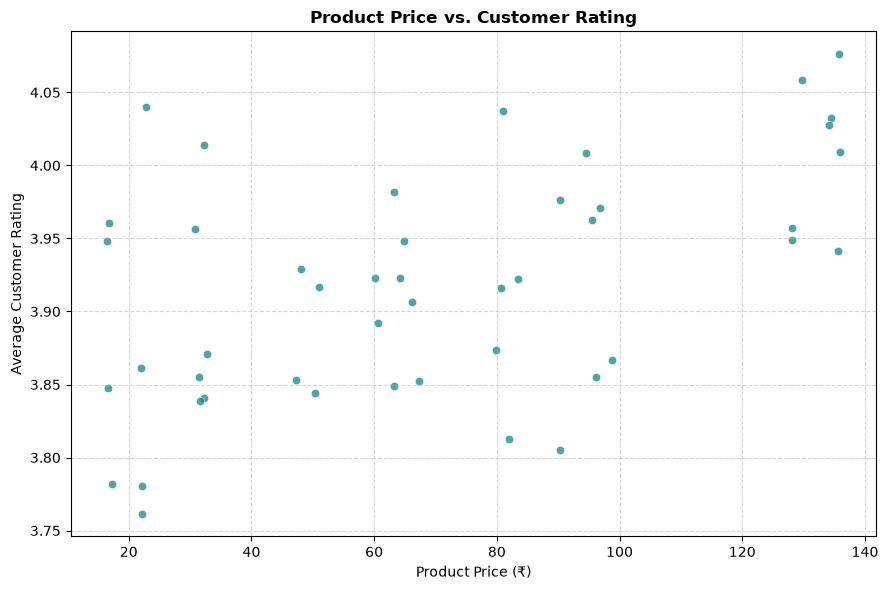

In [57]:
# 13. Do higher-priced products receive different ratings from lower-priced products? — scatter plot.

revenue_rating = df.groupby(['product_name']).agg({
    'unit_price': 'mean',
    'customer_rating': 'mean'
}).reset_index().sort_values(by='unit_price', ascending=False)

plt.figure(figsize=(9, 6))

sns.scatterplot(data=revenue_rating, x='unit_price', y='customer_rating', alpha=0.7, color='teal')

plt.title('Product Price vs. Customer Rating', fontweight='bold')
plt.xlabel('Product Price (₹)')
plt.ylabel('Average Customer Rating')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

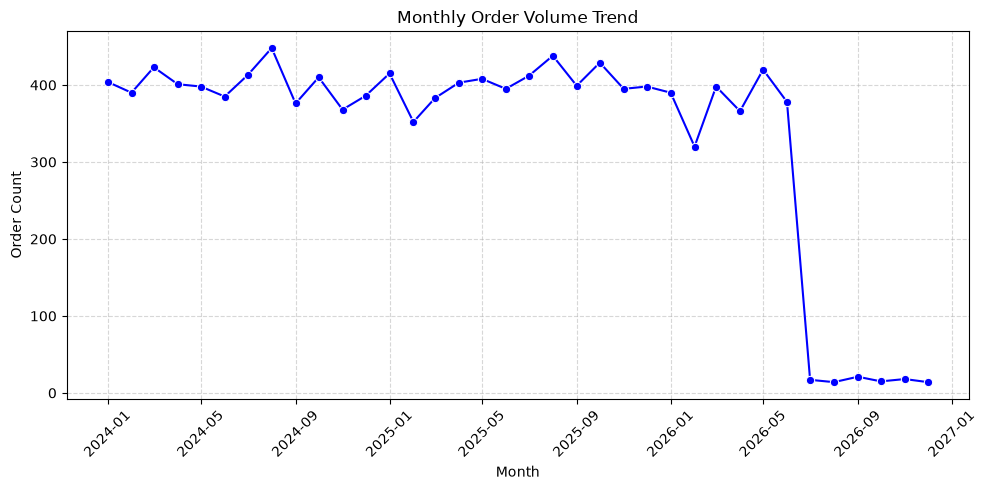

In [64]:
# 14. How does order volume change month by month? — line plot.

revenue_by_month = df.groupby('year_month')['order_id'].count().reset_index(name='order_count')

# 2. Ensure year_month is in datetime format if it isn't already
revenue_by_month['year_month'] = revenue_by_month['year_month'].dt.to_timestamp()

# 3. Create the line plot
plt.figure(figsize=(10, 5))
sns.lineplot(data=revenue_by_month, x='year_month', y='order_count', marker='o', color='b')

plt.title('Monthly Order Volume Trend')
plt.xlabel('Month')
plt.ylabel('Order Count')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

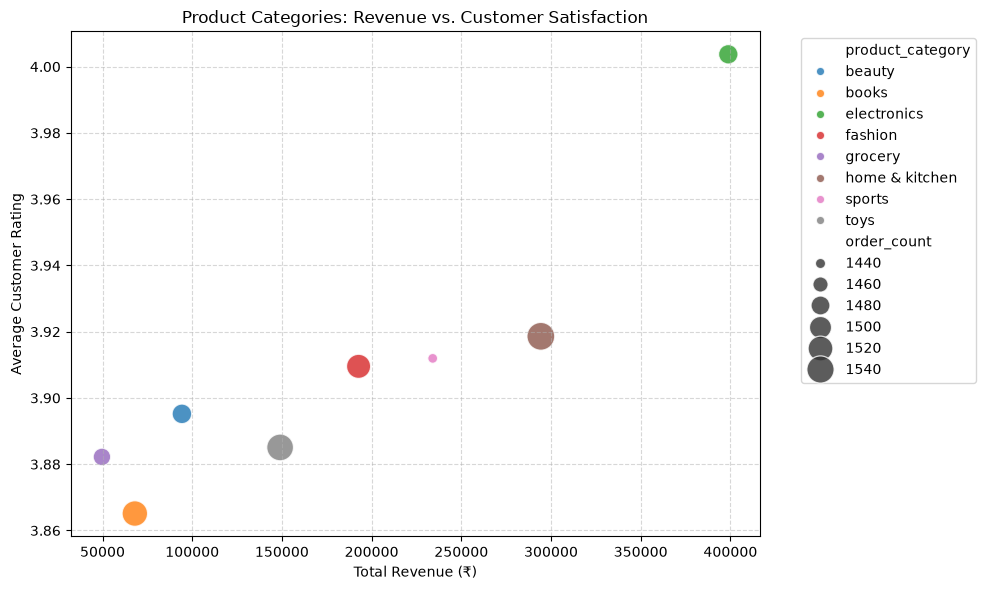

In [65]:
# 15. Which categories combine high revenue with high customer satisfaction? — scatter plot or grouped bar plot.

# 1. Aggregate revenue (sum) and customer rating (mean) by product category
category_perf = df.groupby('product_category').agg({
    'revenue': 'sum',
    'customer_rating': 'mean',
    'order_id': 'count'
}).reset_index().rename(columns={'order_id': 'order_count'})

# 2. Create a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=category_perf, 
    x='revenue', 
    y='customer_rating', 
    size='order_count', 
    sizes=(50, 400), 
    hue='product_category',
    palette='tab10',
    alpha=0.8
)

plt.title('Product Categories: Revenue vs. Customer Satisfaction')
plt.xlabel('Total Revenue (₹)')
plt.ylabel('Average Customer Rating')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_1036\891960172.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='order_status', y='customer_rating', palette='Set2')


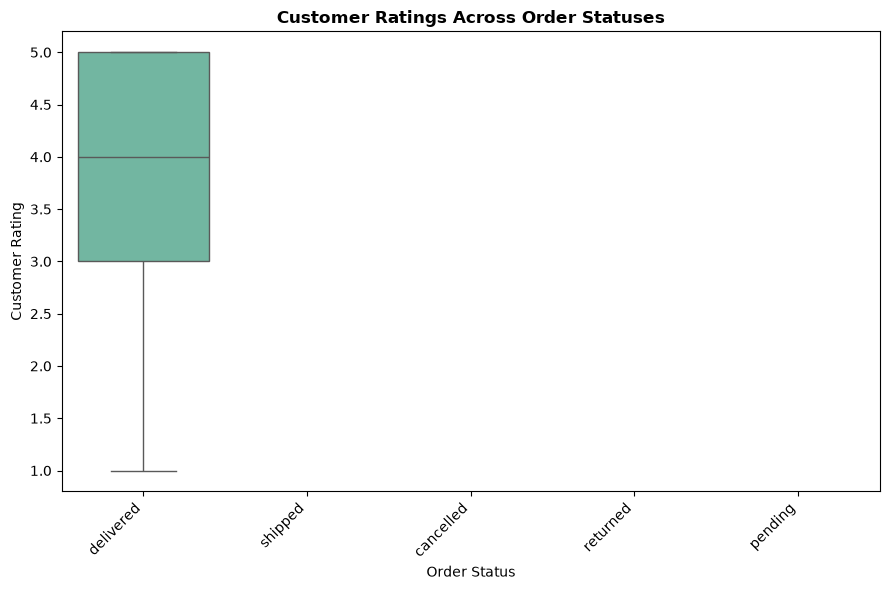

In [61]:
# 16. Are customer ratings different across order statuses? — box plot.

plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x='order_status', y='customer_rating', palette='Set2')

plt.title('Customer Ratings Across Order Statuses', fontweight='bold')
plt.xlabel('Order Status')
plt.ylabel('Customer Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

What is the overall distribution of revenue per order?
Histogram + KDE
Find typical order revenue, skewness, and unusually high-value orders.

Which product categories generate the highest revenue?
Bar plot
Compare category performance and identify major revenue contributors

How does quantity sold vary across product categories?
Box plot
Compare typical quantities, spread, and potential outliers.

How does revenue change over time?
Line plot
Identify growth, seasonal patterns, and revenue peaks using order_date.

Is discount percentage associated with revenue?
Scatter plot
Investigate the relationship between discount_pct and revenue. This is an association, not proof that discounts cause higher sales.

How are customer ratings distributed?
Histogram
Determine whether customer feedback is generally positive or negative.

Which product categories have the highest average customer ratings?
Bar plot
Compare customer satisfaction across product categories.

What proportion of orders belongs to each order status?
Count plot / pie chart
Understand the composition of delivered, cancelled, returned, or other recorded statuses.

Which cities and countries contribute most to revenue?
Horizontal bar plot
Identify strong markets and locations that may need additional attention.

What relationships exist among numerical variables?
Correlation heatmap
Explore relationships between quantity, unit price, discounts, revenue, and customer ratings.

11. Which products have the highest and lowest total revenue? — horizontal bar plot.

12. How does average order revenue differ by payment method? — bar plot.

13. Do higher-priced products receive different ratings from lower-priced products? — scatter plot.

14. How does order volume change month by month? — line plot.

15. Which categories combine high revenue with high customer satisfaction? — scatter plot or grouped bar plot.

16. Are customer ratings different across order statuses? — box plot.